# Step 4 · Annual statistics

**Goal:** turn the 4.4 million daily values of `data/climate.db` into a few numbers per city
and year, and per city, to answer: **are the cities warming, and how fast?**

The functions are in `analysis.stats` (calculations) and `analysis.plots` (charts):
1. Read the database (read-only) and check the data.
2. Statistics per city and year: mean, percentiles, mean of the maxima and minima, anomaly.
3. Summary per city: trends and difference with 1961–1990.
4. Charts: trends, annual means of one city, anomalies of every city, warming stripes.

It does not call the API or use random numbers.

## 1. Configuration and data

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from analysis.plots import plot_annual_means
from analysis.stats import (
    LESS_RELIABLE_BEFORE,
    RECENT_TREND_FROM,
    RECENT_YEARS,
    REFERENCE,
    annual_stats,
    city_summary,
    complete_years,
    read_database,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "climate.db"

FIRST_YEAR = 1940
LAST_YEAR = date.today().year - 1  # last complete year
RECENT = (LAST_YEAR - RECENT_YEARS + 1, LAST_YEAR)

cities, daily = read_database(DB_PATH)
print(f"{len(cities)} complete cities · {len(daily):,} days")
print(
    f"Years {FIRST_YEAR}–{LAST_YEAR} · reference {REFERENCE[0]}–{REFERENCE[1]} "
    f"· recent {RECENT[0]}–{RECENT[1]}"
)

140 complete cities · 4,397,680 days
Years 1940–2025 · reference 1961–1990 · recent 2016–2025


## 2. Checks before calculating

1. **Empty values:** there should be none (the download validated every city).
2. **Complete years:** each year must have 365 days (366 in leap years). An incomplete year, or
   one outside the period, is dropped and shown.
3. **Consistency `t_min ≤ t_mean ≤ t_max`:** a mean outside that range would mean corrupted data.
   It is only counted, not fixed.
4. **Full reference period:** every city needs the 30 years of 1961–1990 for its anomaly.

In [2]:
empty = daily[["t_mean", "t_max", "t_min"]].isna().sum()
print("Empty values:", empty.to_dict())
assert empty.sum() == 0

daily, dropped = complete_years(daily, FIRST_YEAR, LAST_YEAR)
print(f"Dropped city-years: {len(dropped)}")
if len(dropped):
    display(dropped)

inconsistent = (daily["t_min"] > daily["t_mean"]) | (daily["t_mean"] > daily["t_max"])
print(f"Days with t_mean outside [t_min, t_max]: {inconsistent.sum():,}")

reference_years = (
    daily.loc[daily["year"].between(*REFERENCE), ["city_id", "year"]]
    .drop_duplicates()
    .groupby("city_id")
    .size()
)
n_reference = REFERENCE[1] - REFERENCE[0] + 1
assert (reference_years.reindex(cities.index, fill_value=0) == n_reference).all()
print(f"Every city has the {n_reference} reference years")

Empty values: {'t_mean': 0, 't_max': 0, 't_min': 0}


Dropped city-years: 0
Days with t_mean outside [t_min, t_max]: 0


Every city has the 30 reference years


## 3. Statistics per city and year

`annual_stats` computes, for each city and year, from its 365 days:

| Column | What it is |
|---|---|
| `mean` | annual mean of `t_mean` |
| `p05`, `p25`, `p50`, `p75`, `p95` | percentiles of `t_mean` among the days of the year. E.g. `p95`: only 5 % of the days were warmer |
| `max_mean` | annual mean of `t_max` (how hot the days are) |
| `min_mean` | annual mean of `t_min` (how warm the nights are) |
| `anomaly` | `mean` minus the mean of that city in 1961–1990 |

The anomaly makes very different cities comparable: Jakarta and Moscow have very different
means, but both can be +1 °C above their own reference.

In [3]:
annual = annual_stats(daily)
print(f"{len(annual):,} rows (city × year)")
annual.head()

12,040 rows (city × year)


mean     p05   p25   p50   p75     p95   max_mean  \
city_id        year                                                           
addis-ababa-et 1940  13.670765  11.725  13.1  13.8  14.4  15.175  19.638251   
               1941  14.327123  11.600  13.1  13.9  15.6  17.880  20.972603   
               1942  13.811233  11.800  12.9  13.6  14.8  16.500  20.239726   
               1943  13.519452  11.140  12.5  13.1  14.3  16.680  19.764110   
               1944  14.040984  12.400  13.3  13.9  14.8  16.100  20.512295   

                     min_mean   anomaly  
city_id        year                      
addis-ababa-et 1940  8.624590 -1.062093  
               1941  8.371781 -0.405734  
               1942  7.923836 -0.921625  
               1943  8.030685 -1.213406  
               1944  8.244809 -0.691874

## 4. Summary per city

`city_summary`:
- **`trend_decade`:** slope of the line that best fits the annual `mean` (linear regression with
  `numpy.polyfit`), in °C per decade, with every year from 1940.
- **`recent_trend`:** the same slope, only from 1975. The global mean temperature was almost
  flat between 1945 and 1975 and has risen steadily since. Over the whole period both phases are
  mixed and the trend can come out very low.
- **`difference`:** mean of the last 10 years minus mean of 1961–1990, the same as the mean
  anomaly of the recent years. Easier to explain than a trend: "the last 10 years were X °C
  warmer than 1961–1990".
- **`warmest_year`:** the year with the highest `mean`.

In [4]:
summary = cities[["name", "country", "latitude_band", "coastal"]].join(
    city_summary(annual)
)
summary.sort_values("difference", ascending=False).round(2).head(10)

,name,country,latitude_band,coastal,first_year,last_year,reference_mean,trend_decade,recent_trend,difference,warmest_year
id,,,,,,,,,,,
norilsk-ru,Norilsk,Russia,polar_north,0,1940,2025,-9.54,0.37,0.62,3.17,2020
riyadh-sa,Riyadh,Saudi Arabia,subtropical_north,0,1940,2025,25.03,0.43,0.56,2.44,2021
arak-dz,Arak,Algeria,subtropical_north,0,1940,2025,25.05,0.39,0.54,2.39,2021
anchorage-us,Anchorage,United States of America,subpolar_north,1,1940,2025,2.45,0.34,0.41,2.29,2019
bechar-dz,Béchar,Algeria,subtropical_north,0,1940,2025,21.07,0.40,0.52,2.28,2024
isfahan-ir,Isfahan,Iran,subtropical_north,0,1940,2025,15.96,0.31,0.57,2.20,2024
st-petersburg-ru,St. Petersburg,Russia,temperate_north,1,1940,2025,4.23,0.29,0.59,2.19,2020
murmansk-ru,Murmansk,Russia,polar_north,1,1940,2025,-0.22,0.27,0.56,2.16,2022
tambov-ru,Tambov,Russia,temperate_north,0,1940,2025,5.46,0.37,0.58,2.16,2025


### Check with Phoenix

In the original project, the decade means of Phoenix were computed directly in SQL over the
daily data: **1940s → 21.61 °C** and **2020s → 24.13 °C**. Here they come from the annual means
and must match (except for a tiny difference, because leap years weigh one day more).

In [5]:
phoenix = annual.loc["phoenix-us", "mean"]
decades = phoenix.groupby((phoenix.index // 10) * 10).mean().round(2)
print(decades.to_string())
assert abs(decades.iloc[0] - 21.61) < 0.02 and abs(decades.iloc[-1] - 24.13) < 0.02
print("OK: same as the original project")

year
1940    21.61
1950    22.14
1960    21.95
1970    22.14
1980    22.70
1990    22.89
2000    23.60
2010    23.85
2020    24.13
OK: same as the original project


## 5. How many cities warm, and how fast

Histogram of the trends: with every year and only since 1975.

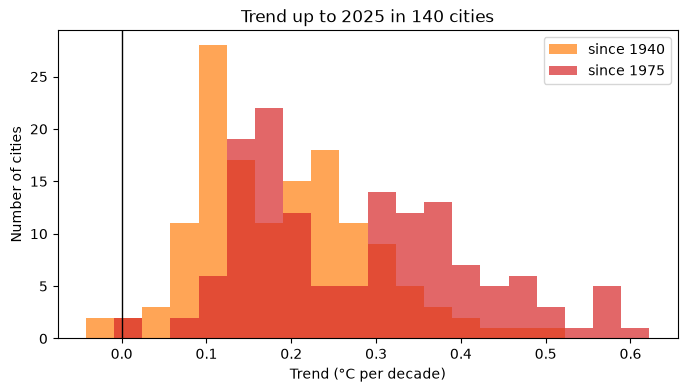

Warming since 1940: 137 of 140
Median trend since 1940: +0.19 °C/decade
Median trend since 1975: +0.27 °C/decade
Median difference 2016–2025 vs 1961–1990: +1.11 °C
Cities whose warmest year is 2015 or later: 109 of 140


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
edges = np.histogram_bin_edges(summary[["trend_decade", "recent_trend"]], bins=20)
ax.hist(
    summary["trend_decade"],
    bins=edges,
    color="tab:orange",
    alpha=0.7,
    label=f"since {FIRST_YEAR}",
)
ax.hist(
    summary["recent_trend"],
    bins=edges,
    color="tab:red",
    alpha=0.7,
    label=f"since {RECENT_TREND_FROM}",
)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Trend (°C per decade)")
ax.set_ylabel("Number of cities")
ax.set_title(f"Trend up to {LAST_YEAR} in {len(summary)} cities")
ax.legend()
plt.show()

print(
    f"Warming since {FIRST_YEAR}: {(summary['trend_decade'] > 0).sum()} of {len(summary)}"
)
print(
    f"Median trend since {FIRST_YEAR}: {summary['trend_decade'].median():+.2f} °C/decade"
)
print(
    f"Median trend since {RECENT_TREND_FROM}: {summary['recent_trend'].median():+.2f} °C/decade"
)
print(
    f"Median difference {RECENT[0]}–{RECENT[1]} vs {REFERENCE[0]}–{REFERENCE[1]}: "
    f"{summary['difference'].median():+.2f} °C"
)
recent_records = (summary["warmest_year"] >= 2015).sum()
print(f"Cities whose warmest year is 2015 or later: {recent_records} of {len(summary)}")

## 6. Annual means of a city

`plot_annual_means`: three lines, one point per year:
- **red:** annual mean of the daily maxima, how hot the days are;
- **black:** annual mean of the daily mean temperature;
- **blue:** annual mean of the daily minima, how warm the nights are.

The dashed line is the trend since 1975 and the light blue band, the reference period. If the
blue line rises more than the red one, nights warm faster than days.

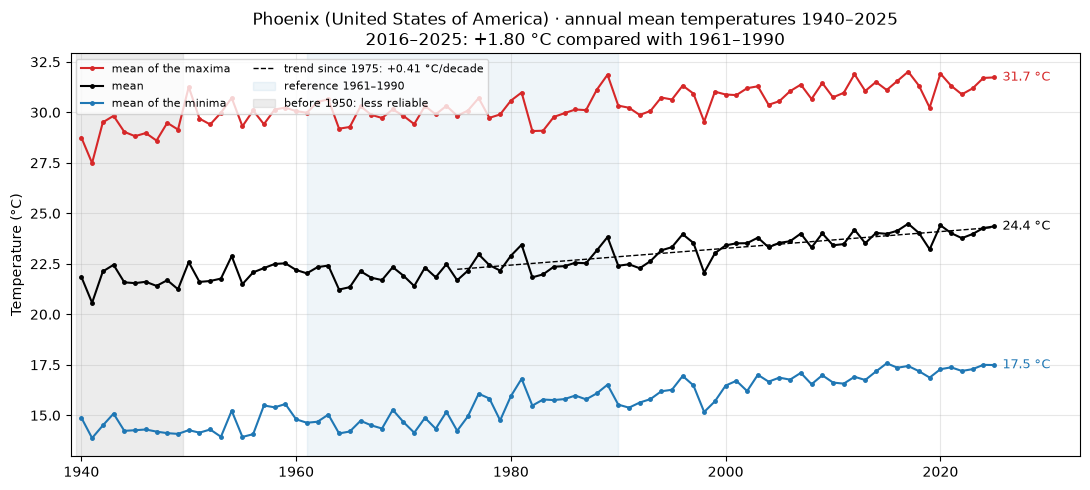

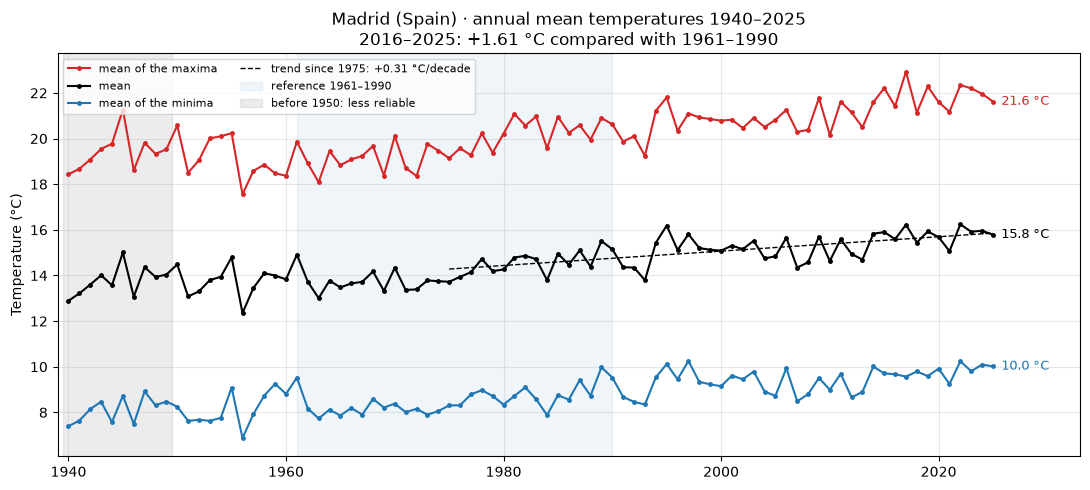

In [7]:
for city_id in ["phoenix-us", "madrid-es"]:
    s = summary.loc[city_id]
    plot_annual_means(annual, summary, city_id, title=f"{s['name']} ({s['country']})")
    plt.show()

## 7. The anomalies of every city on one axis

One grey line per city (10-year moving average, to remove the noise of single years) and, in
red, the **median** of all of them. Anomalies can share an axis because each one starts from its
own 1961–1990 reference.

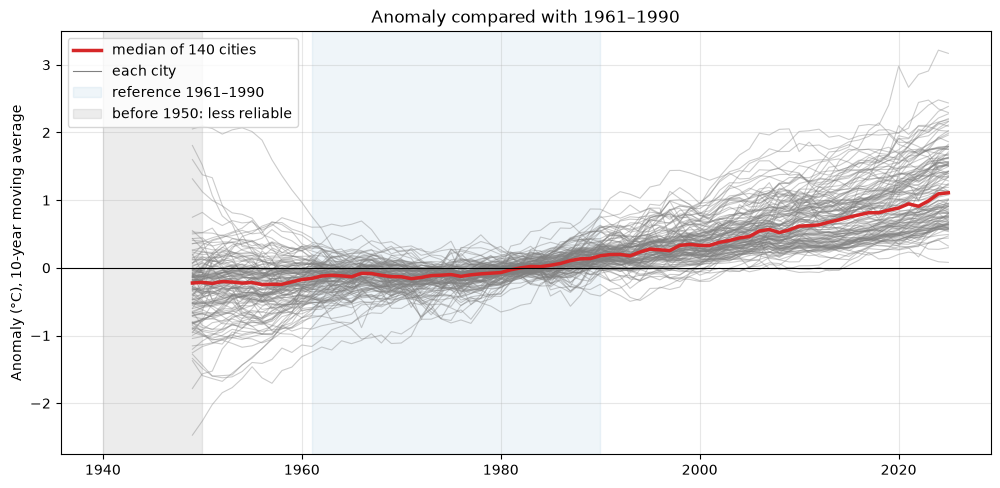

Moving average in 2025: median +1.11 °C
Warmest: Norilsk +3.17, Riyadh +2.44, Arak +2.39
Least warm: Osorno +0.08, Adelaide +0.30, Lima +0.32


In [8]:
WINDOW = 10
moving = (
    annual["anomaly"]
    .groupby(level="city_id")
    .transform(lambda s: s.rolling(WINDOW).mean())
    .unstack("city_id")  # one column per city, one row per year
)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(moving.index, moving, color="grey", linewidth=0.8, alpha=0.4)
ax.plot(
    moving.index,
    moving.median(axis=1),
    color="tab:red",
    linewidth=2.5,
    label=f"median of {moving.shape[1]} cities",
)
ax.plot([], [], color="grey", linewidth=0.8, label="each city")  # legend entry
ax.axhline(0, color="black", linewidth=0.8)
ax.axvspan(
    REFERENCE[0],
    REFERENCE[1],
    color="tab:blue",
    alpha=0.07,
    label=f"reference {REFERENCE[0]}–{REFERENCE[1]}",
)
ax.axvspan(
    FIRST_YEAR,
    LESS_RELIABLE_BEFORE,
    color="grey",
    alpha=0.15,
    label=f"before {LESS_RELIABLE_BEFORE}: less reliable",
)
ax.set_ylabel(f"Anomaly (°C), {WINDOW}-year moving average")
ax.set_title(f"Anomaly compared with {REFERENCE[0]}–{REFERENCE[1]}")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.show()

last = moving.iloc[-1].sort_values()
print(f"Moving average in {moving.index[-1]}: median {last.median():+.2f} °C")
print(
    "Warmest:",
    ", ".join(f"{summary.loc[i, 'name']} {v:+.2f}" for i, v in last[::-1][:3].items()),
)
print(
    "Least warm:",
    ", ".join(f"{summary.loc[i, 'name']} {v:+.2f}" for i, v in last[:3].items()),
)

## 8. Warming stripes

One row per city and one colour per year: blue if the year was colder than 1961–1990, red if
it was warmer. Cities are sorted from the largest to the smallest `difference` (in brackets).

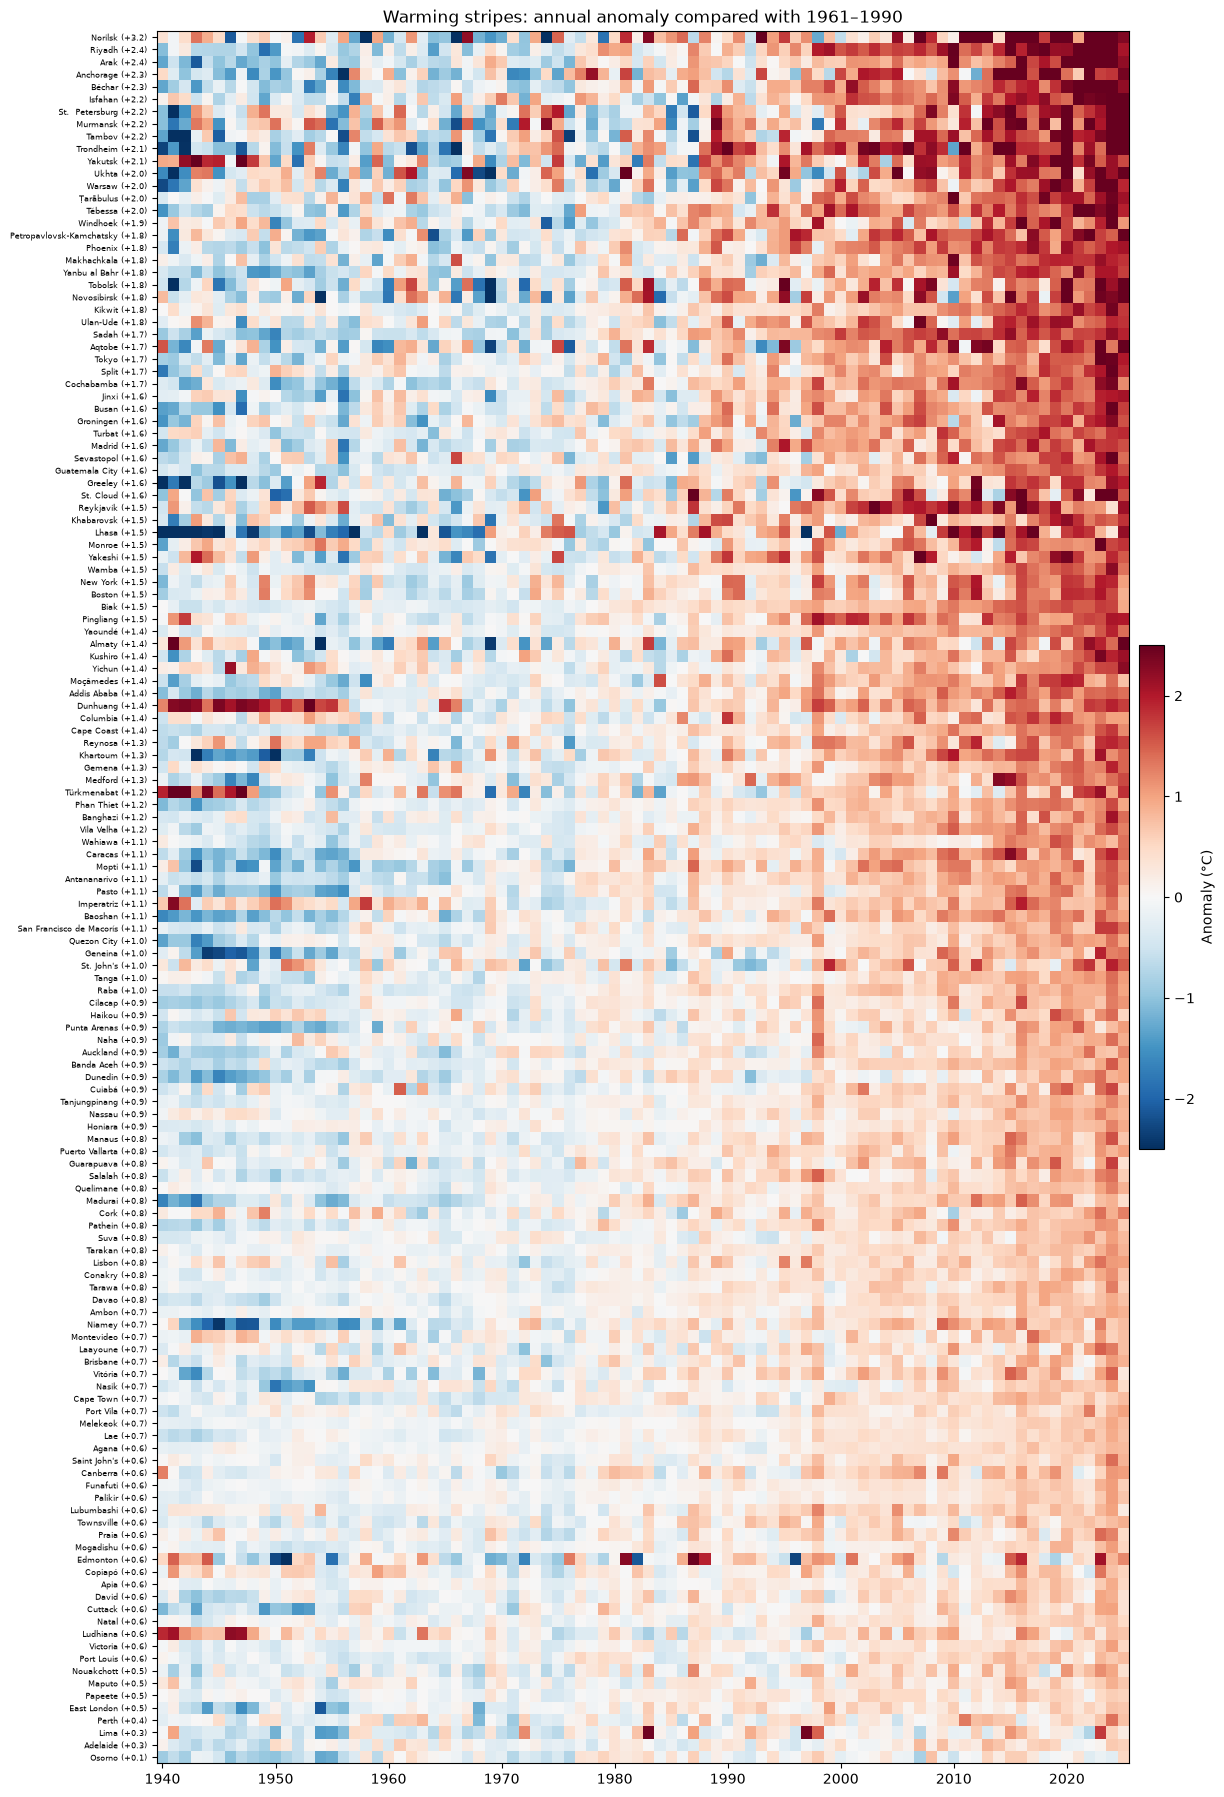

In [9]:
order = summary.sort_values("difference", ascending=False).index
stripes = (
    annual["anomaly"].unstack("year").loc[order]
)  # one row per city, one column per year
limit = 2.5  # °C: from here on, the strongest colour

fig, ax = plt.subplots(figsize=(13, 0.15 * len(order) + 1.5))
image = ax.imshow(
    stripes,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    extent=[stripes.columns[0] - 0.5, stripes.columns[-1] + 0.5, len(order), 0],
)
ax.set_yticks(np.arange(len(order)) + 0.5)
ax.set_yticklabels(
    [f"{summary.loc[i, 'name']} ({summary.loc[i, 'difference']:+.1f})" for i in order],
    fontsize=6,
)
ax.set_title(
    f"Warming stripes: annual anomaly compared with {REFERENCE[0]}–{REFERENCE[1]}"
)
fig.colorbar(image, ax=ax, label="Anomaly (°C)", fraction=0.025, pad=0.01)
plt.show()

## 9. Who warms more: groups, days and nights

- **Coastal vs inland** and **latitude band**: median `difference` of each group.
- **Days vs nights:** difference between the last 10 years and 1961–1990 of the annual mean of
  the maxima and of the minima.

In [10]:
groups = pd.concat(
    {
        "coastal": summary.groupby(summary["coastal"].map({1: "coastal", 0: "inland"}))[
            "difference"
        ].agg(["median", "count"]),
        "band": summary.groupby(
            summary["latitude_band"].str.replace("_north|_south", "", regex=True)
        )["difference"].agg(["median", "count"]),
    }
)
display(groups.round(2))

years = annual.index.get_level_values("year")
recent = annual[years >= RECENT[0]].groupby("city_id")[["max_mean", "min_mean"]].mean()
reference = (
    annual[(years >= REFERENCE[0]) & (years <= REFERENCE[1])]
    .groupby("city_id")[["max_mean", "min_mean"]]
    .mean()
)
days_nights = (recent - reference).rename(
    columns={"max_mean": "days (max)", "min_mean": "nights (min)"}
)
print("Median warming, last 10 years vs 1961–1990:")
print(days_nights.median().round(2).to_string())
nights_faster = (days_nights["nights (min)"] > days_nights["days (max)"]).sum()
print(f"Cities where nights warm more than days: {nights_faster} of {len(days_nights)}")

median  count
coastal coastal        0.87     80
        inland         1.46     60
band    polar          2.67      2
        subpolar       2.09      5
        subtropical    1.16     28
        temperate      1.55     38
        tropical       0.83     67

Median warming, last 10 years vs 1961–1990:
days (max)      1.11
nights (min)    1.11
Cities where nights warm more than days: 60 of 140


## Conclusions

**Data quality**
- No empty values, no incomplete years and no day with `t_mean` outside [`t_min`, `t_max`] in
  the 140 cities (4,397,680 days); all of them have the 30 reference years.
- The decade means of Phoenix match the original project (21.61 °C in the 1940s → 24.13 °C in
  the 2020s).

**Every city is warmer than in 1961–1990**
- The `difference` (2016–2025 vs 1961–1990) is positive in **all 140 cities**, with a median of
  **+1.11 °C**.
- Median trend: +0.19 °C/decade since 1940 and **+0.27 since 1975**. Warming is concentrated
  after 1980: in the anomaly chart the lines are almost flat until then and rise afterwards.
- In **109 of the 140 cities** the warmest year is 2015 or later.
- Only 3 cities have a slightly negative trend since 1940 (Ludhiana −0.04, Dunhuang −0.02 and
  Türkmenabat −0.01 °C/decade), and all three warm since 1975 (+0.20 to +0.36). Their stripes
  show very warm 1940s, which flattens the line (see the precautions). Osorno is the only one
  with a flat trend since 1975 (−0.01).

**Most and least**
- **Most:** Norilsk (+3.17 °C), Riyadh (+2.44), Arak (+2.39), Anchorage (+2.29) and Béchar (+2.28):
  high latitudes and inland deserts.
- **Least:** Osorno (+0.08), Adelaide (+0.30), Lima (+0.32), Perth (+0.44) and East London (+0.47):
  coastal cities of the southern hemisphere, several next to cold ocean currents (Humboldt in
  Lima): the ocean slows down the warming.
- By group: **inland +1.46 °C** (60 cities) against **coastal +0.87** (80); polar +2.67 (2),
  subpolar +2.09 (5), temperate +1.55 (38), subtropical +1.16 (28) and tropical +0.83 (67).
  The farther from the equator and from the sea, the more warming.

**Days and nights**
- Overall they rise the same: median +1.11 °C the maxima and +1.11 °C the minima. But it depends
  on the city: in 60 of the 140 the nights warm more than the days.

**Precautions**
- Before 1950 ERA5 has far fewer observations. Some cities (Lhasa, Dunhuang, Türkmenabat,
  Ludhiana, Edmonton) have blocks of years before ~1960 that are much colder or warmer than the
  rest, which could come from the model and not from the climate; they affect the trend since
  1940 more than the trend since 1975 or the `difference`.
- Each city is an ERA5 cell of about 25 km, not a weather station: it does not capture the urban
  heat island well.
- Vila Velha's data come from a point in Amapá (see step 2).